# HW2. Деревья и ансамбли: реакция пользователя

Все модели оцениваются на одних и тех же 5 фолдах: `StratifiedGroupKFold(5, shuffle=True,
random_state=42)` по группам почти-дубликатов на всех 3000 размеченных диалогах.
Метрика — macro-F1 по диалогам, среднее по фолдам. Результаты CV кэшируются в
`artifacts/cv/` (`python experiments.py` считает всё заново).

Код: `splits.py` — данные и фолды, `cv.py` — цикл CV, `old_models.py` — модели HW1,
`trees.py` — признаки реплик и деревья, `turn_stack.py` — стекинг по репликам,
`experiments.py` — список экспериментов, `report.py` — графики.

In [1]:
import json, pickle, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_sample_weight

import experiments as E
import old_models as om
import trees as T
import turn_stack as S
from cv import run_cv, summary_table, paired_delta, macro_f1, REACTIONS
from report import compare_plot, paired_plot
from splits import load_data, iter_folds

pd.set_option("display.precision", 4)
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

## 1. Данные и фолды

Реакция диалога — последняя ненейтральная реакция реплик пользователя, иначе neutral.
Почти-дубликаты (TF-IDF реплик пользователя, косинус ≥ 0.95) объединены в группы
и не попадают в разные фолды.

In [2]:
df = load_data()
y = df["reaction"].to_numpy()
print("диалогов:", len(df), " групп:", df["group"].nunique())
display(pd.crosstab(df["fold"], df["reaction"], margins=True))

диалогов: 3000  групп: 2987


reaction,negative,neutral,positive,All
fold,,,,
0,185,355,60,600
1,185,355,61,601
2,184,355,61,600
3,184,355,61,600
4,185,354,60,599
All,923,1774,303,3000


## 2. Старые модели на тех же фолдах

Модели HW1 переобучаются на каждом фолде с гиперпараметрами HW1 без изменений
(параметры из `artifacts/hw1_*.joblib` через `clone`, предсказание — тем же кодом
`reaction_models`, что в `solution.ipynb`).

Проверка воспроизведения (обучение на тех же данных, что артефакт): NB, LR, SVM
совпадают с сохранёнными на 100% предсказаний; база 909 на сохранённых
`train_dialog_ids` — 99.8%; стек 909 — 96% (код обучения 909 не сохранился,
воспроизведение приближённое). `hw1_decision_2x` и `hw1_score_stacking_lr` в
`artifacts/` обучены на 2400 диалогах train-части HW1, тот сплит не восстановить.

In [3]:
old = {name: run_cv(name, make, df, family="HW1") for name, make in om.OLD_MODELS.items()}

hw1_naive_bayes              CV macro-F1 0.5402 ± 0.0176  по фолдам [0.545 0.531 0.537 0.517 0.57 ]  fit 4.7 с, predict 0.62 с
hw1_logistic_regression      CV macro-F1 0.6269 ± 0.0180  по фолдам [0.6   0.633 0.632 0.616 0.654]  fit 5.1 с, predict 0.62 с
hw1_svm                      CV macro-F1 0.6309 ± 0.0229  по фолдам [0.597 0.63  0.627 0.633 0.669]  fit 4.8 с, predict 0.65 с
hw1_decision_2x              CV macro-F1 0.7295 ± 0.0117  по фолдам [0.718 0.722 0.727 0.728 0.752]  fit 12.4 с, predict 1.71 с
hw1_score_stacking_lr        CV macro-F1 0.6794 ± 0.0185  по фолдам [0.686 0.671 0.651 0.708 0.681]  fit 63.0 с, predict 1.73 с
hw1_grisha_909               CV macro-F1 0.6867 ± 0.0128  по фолдам [0.695 0.664 0.69  0.702 0.682]  fit 3.3 с, predict 1.67 с
hw1_stack_909                CV macro-F1 0.6658 ± 0.0156  по фолдам [0.667 0.656 0.66  0.695 0.651]  fit 17.5 с, predict 1.68 с


## 3. Признаки реплик

Объект — реплика пользователя j ≥ 1 (у реплики есть метка реакции). Признаки учатся
только на обучающей части фолда:
- `raw` — TF-IDF 42 000: user слова 1–2 (12k), user символы 3–5 (18k),
  ответ ассистента до реплики (6k, вес 0.4), ответ после (6k, вес 0.4);
- `turn` — 137 плотных: SVD(100) от `raw` + 37 числовых (структура, длины ответов,
  9 регулярок × 3 источника, пересечения слов).

Метка диалога: последняя реплика с max(P(neg), P(pos)) ≥ 0.5, класс — больший из
P(neg), P(pos); если такой нет — neutral.

In [4]:
fit0, val0 = df[df.fold != 0].reset_index(drop=True), df[df.fold == 0].reset_index(drop=True)
start = time.perf_counter()
rep0 = T.features(fit0)
print(f"построение признаков на фолде 0: {time.perf_counter() - start:.1f} с")
print("raw:", rep0.train["raw"].shape, " turn:", rep0.train["turn"].shape)
display(rep0.train["pairs"]["reaction"].value_counts().to_frame("реплик"))

построение признаков на фолде 0: 9.9 с
raw: (13667, 42000)  turn: (13667, 137)


,реплик
reaction,
neutral,11332
negative,1889
positive,446


## 4. Деревья и ансамбли

Параметры из ноутбука коллег, у всех веса классов `balanced`: Tree (depth 6, leaf 10),
Bagging (100 полных деревьев), Forest (100, leaf 3, sqrt), Forest_tfidf (то же на `raw`),
HGB / LightGBM / CatBoost (depth 4, lr 0.07, 200 итераций).

In [5]:
new = {name: run_cv(name, make, df, family=E.FAMILY[name]) for name, make in E.TREES.items()}
display(summary_table(list(new.values()), y).drop(columns=["fit_seconds", "predict_seconds"]))

Tree                         CV macro-F1 0.6039 ± 0.0141  по фолдам [0.589 0.585 0.614 0.619 0.611]  fit 10.3 с, predict 1.23 с
Bagging                      CV macro-F1 0.6828 ± 0.0155  по фолдам [0.68  0.658 0.695 0.678 0.703]  fit 9.9 с, predict 1.51 с
Forest                       CV macro-F1 0.7057 ± 0.0147  по фолдам [0.696 0.702 0.734 0.702 0.695]  fit 0.7 с, predict 1.31 с
Forest_tfidf                 CV macro-F1 0.7117 ± 0.0076  по фолдам [0.701 0.712 0.721 0.705 0.719]  fit 1.1 с, predict 1.35 с
HGB                          CV macro-F1 0.6940 ± 0.0164  по фолдам [0.689 0.681 0.724 0.679 0.697]  fit 6.6 с, predict 1.45 с
LightGBM                     CV macro-F1 0.6876 ± 0.0238  по фолдам [0.691 0.655 0.713 0.666 0.713]  fit 1.4 с, predict 1.33 с
CatBoost                     CV macro-F1 0.6752 ± 0.0092  по фолдам [0.683 0.664 0.689 0.668 0.673]  fit 0.8 с, predict 1.38 с


,family,cv_macro_f1,std,accuracy,balanced_accuracy,recall_positive,recall_negative
model,,,,,,,
Forest_tfidf,дерево/ансамбль,0.7117,0.0076,0.7723,0.6813,0.4950,0.6826
Forest,дерево/ансамбль,0.7057,0.0147,0.7743,0.6763,0.4488,0.7237
HGB,дерево/ансамбль,0.6940,0.0164,0.7493,0.6944,0.5248,0.7941
LightGBM,дерево/ансамбль,0.6876,0.0238,0.7367,0.6960,0.5545,0.7974
Bagging,дерево/ансамбль,0.6828,0.0155,0.7503,0.6717,0.4686,0.7454
CatBoost,дерево/ансамбль,0.6752,0.0092,0.7233,0.7104,0.6436,0.7801
Tree,дерево/ансамбль,0.6039,0.0141,0.6600,0.6582,0.6172,0.7226


## 5. Путь подбора, включая неудачи

Каждая строка — одно изменение относительно «родителя». Все варианты оценены на тех же
5 фолдах. Выбор по внешней CV даёт оптимистичную оценку выбранного варианта: при
разбросе фолдов ±0.01–0.02 разница меньше ~0.01 не значима.

In [6]:
new.update({name: run_cv(name, make, df, family=E.FAMILY[name], verbose=False) for name, make in E.ALL.items()})
res = {**old, **new}
f1 = lambda n: res[n]["folds"].macro_f1.to_numpy()

PATH = [
    ("Forest_tfidf", "Forest", "TF-IDF вместо SVD-признаков"),
    ("Forest_tfidf_leaf1", "Forest_tfidf", "min_samples_leaf 3 → 1"),
    ("Forest_tfidf_leaf6", "Forest_tfidf", "min_samples_leaf 3 → 6"),
    ("Forest_tfidf_mf0.02", "Forest_tfidf", "max_features sqrt → 0.02"),
    ("Forest_tfidf_300", "Forest_tfidf", "100 → 300 деревьев"),
    ("Forest_tfidf_unbalanced", "Forest_tfidf", "без весов классов"),
    ("LightGBM_d3", "LightGBM", "глубина 4 → 3"),
    ("LightGBM_d6", "LightGBM", "глубина 4 → 6"),
    ("LightGBM_lr0.03_n600", "LightGBM", "lr 0.07 → 0.03, 600 итераций"),
    ("LightGBM_tfidf", "LightGBM", "TF-IDF вместо SVD-признаков"),
    ("LightGBM_svm", "LightGBM", "+ OOF-оценки SVM из HW1"),
    ("Forest_svm", "Forest", "+ OOF-оценки SVM из HW1"),
    ("Forest_dialog_tfidf", "Forest_tfidf", "TF-IDF всего диалога вместо реплик"),
    ("Bagging_decision_2x", "hw1_decision_2x", "бэггинг: 10 копий на бутстрепе"),
    ("Stack_lr", "hw1_decision_2x", "стек по диалогу: 5 баз, мета LR balanced"),
    ("Stack_lr_unbalanced", "Stack_lr", "мета LR без весов классов"),
    ("Stack_d2x_forest", "Stack_lr", "только Decision_2x + Forest_tfidf"),
    ("hw2_stack", "Stack_lr_unbalanced", "стек по репликам: SVM + Forest_300 + LightGBM_d6"),
]
path = pd.DataFrame([dict(model=n, parent=p, change=c, cv_macro_f1=f1(n).mean(),
                          delta_parent=f1(n).mean() - f1(p).mean(), better_folds=f"{(f1(n) > f1(p)).sum()}/5",
                          delta_decision_2x=f1(n).mean() - f1("hw1_decision_2x").mean())
                     for n, p, c in PATH]).set_index("model")
display(path)

,parent,change,cv_macro_f1,delta_parent,better_folds,delta_decision_2x
model,,,,,,
Forest_tfidf,Forest,TF-IDF вместо SVD-признаков,0.7117,0.0061,4/5,-0.0178
Forest_tfidf_leaf1,Forest_tfidf,min_samples_leaf 3 → 1,0.7051,-0.0066,2/5,-0.0244
Forest_tfidf_leaf6,Forest_tfidf,min_samples_leaf 3 → 6,0.7051,-0.0066,1/5,-0.0244
Forest_tfidf_mf0.02,Forest_tfidf,max_features sqrt → 0.02,0.7076,-0.0041,2/5,-0.0219
Forest_tfidf_300,Forest_tfidf,100 → 300 деревьев,0.7160,0.0043,4/5,-0.0135
Forest_tfidf_unbalanced,Forest_tfidf,без весов классов,0.6399,-0.0719,0/5,-0.0896
LightGBM_d3,LightGBM,глубина 4 → 3,0.6706,-0.0171,0/5,-0.0590
LightGBM_d6,LightGBM,глубина 4 → 6,0.7147,0.0271,5/5,-0.0148
LightGBM_lr0.03_n600,LightGBM,"lr 0.07 → 0.03, 600 итераций",0.6831,-0.0046,2/5,-0.0464


**Порог правила последней реакции** — по сохранённым вероятностям реплик, без переобучения.

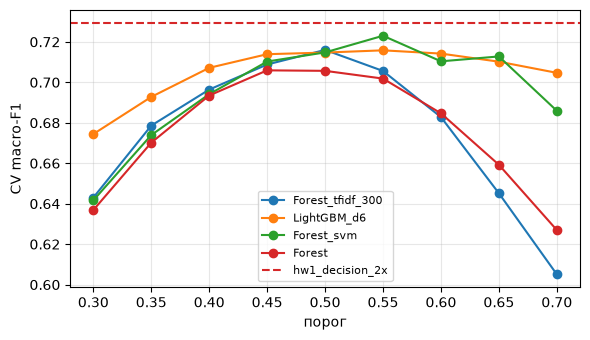

In [7]:
grid = np.arange(0.3, 0.71, 0.05)
fig, ax = plt.subplots(figsize=(6, 3.5))
for name in ["Forest_tfidf_300", "LightGBM_d6", "Forest_svm", "Forest"]:
    curve = [np.mean([macro_f1(y[idx], T.last_reaction(pos, p, len(idx), t)[0]) for idx, pos, p in res[name]["turns"]])
             for t in grid]
    ax.plot(grid, curve, marker="o", label=name)
ax.axhline(f1("hw1_decision_2x").mean(), color="#d62728", ls="--", label="hw1_decision_2x")
ax.set_xlabel("порог"); ax.set_ylabel("CV macro-F1"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIG / "threshold.png", dpi=130); plt.show()

## 6. Стекинг на OOF по репликам (`hw2_stack`)

Разбор ошибок (раздел 8) показал: Decision_2x и деревья расходятся на ~13% диалогов,
и расхождение — в том, *какая реплика* считается реакцией. Поэтому стекинг строится на
уровне реплик, а не по сводкам диалога:

1. базы — два LinearSVC из `hw1_decision_2x` (старая модель), Forest_tfidf_300, LightGBM_d6;
2. вход меты для реплики — 2 оценки SVM + 3 + 3 вероятности деревьев, для обучения
   меты — out-of-fold (3 внутренних фолда по группам внутри обучающей части);
3. мета — логистическая регрессия; метка диалога — правило последней реакции с
   порогом, подобранным по OOF-вероятностям меты на обучающей части.

Варианты меты ниже считаются по один раз сохранённым выходам баз (`level1_turns`).

In [8]:
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

L1T = S.level1_turns(df, E.STACK_TREES)
LR = lambda **kw: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, **kw))
SVM, FOREST, LGBM = [0, 1], [2, 3, 4], [5, 6, 7]
variants = {
    "LR: только SVM": (LR(), SVM),
    "LR: SVM + Forest": (LR(), SVM + FOREST),
    "LR: SVM + LightGBM": (LR(), SVM + LGBM),
    "LR: SVM + Forest + LightGBM (hw2_stack)": (LR(), SVM + FOREST + LGBM),
    "LR balanced: SVM + Forest + LightGBM": (LR(class_weight="balanced"), SVM + FOREST + LGBM),
    "LightGBM-мета: SVM + Forest + LightGBM": (LGBMClassifier(max_depth=3, num_leaves=8, learning_rate=0.05,
                                                              n_estimators=200, verbosity=-1, random_state=42),
                                               SVM + FOREST + LGBM),
}
rows = []
for name, (meta, cols) in variants.items():
    pred, thr = S.oof_predict(df, L1T, meta, cols)
    s = np.array([macro_f1(y[v], pred[v]) for _, _, v in iter_folds(df)])
    rows.append(dict(meta=name, cv_macro_f1=s.mean(), std=s.std(), better_than_d2x=f"{(s > f1('hw1_decision_2x')).sum()}/5",
                     thresholds=np.round(thr, 3)))
display(pd.DataFrame(rows).set_index("meta"))

,cv_macro_f1,std,better_than_d2x,thresholds
meta,,,,
LR: только SVM,0.7193,0.0152,1/5,"[0.4, 0.475, 0.375, 0.4, 0.425]"
LR: SVM + Forest,0.7350,0.0144,3/5,"[0.375, 0.475, 0.35, 0.425, 0.325]"
LR: SVM + LightGBM,0.7295,0.0182,2/5,"[0.45, 0.475, 0.4, 0.35, 0.425]"
LR: SVM + Forest + LightGBM (hw2_stack),0.7330,0.0154,2/5,"[0.425, 0.4, 0.475, 0.5, 0.5]"
LR balanced: SVM + Forest + LightGBM,0.7132,0.0095,1/5,"[0.7, 0.7, 0.7, 0.675, 0.7]"
LightGBM-мета: SVM + Forest + LightGBM,0.7342,0.0167,4/5,"[0.4, 0.35, 0.375, 0.35, 0.35]"


Мета на одних SVM-оценках — это перекалиброванный Decision_2x; разница между ней и
полным стеком показывает вклад деревьев. Мета LightGBM в среднем по 4 seed даёт 0.731,
не лучше LR, поэтому в `hw2_stack` взята более простая LR.

,hw2_stack,hw1_decision_2x,delta
fold,,,
0,0.7109,0.7179,-0.0069
1,0.7483,0.7220,0.0263
2,0.7396,0.7275,0.0122
3,0.7184,0.7285,-0.0100
4,0.7475,0.7517,-0.0042
mean,0.7330,0.7295,0.0035


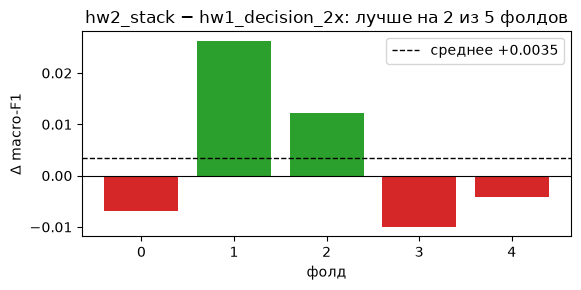

In [9]:
paired = paired_delta(res["hw2_stack"], res["hw1_decision_2x"])
display(paired)
paired_plot(paired, "hw2_stack", "hw1_decision_2x", FIG / "paired_delta.png")

## 7. Сводная таблица и сравнение

Качество — по 5 фолдам. `cv_macro_f1_equal` — macro-F1 при равных долях классов
(веса объектов `balanced`), см. раздел 10.

In [10]:
w_eq = compute_sample_weight("balanced", y)
table = summary_table(list(res.values()), y).drop(columns=["fit_seconds", "predict_seconds"])
table.insert(2, "cv_macro_f1_equal", [np.mean([macro_f1(y[v], res[n]["pred"][v], w_eq[v]) for _, _, v in iter_folds(df)])
                                      for n in table.index])
display(table)
table.to_csv("artifacts/summary_table.csv")

,family,cv_macro_f1,cv_macro_f1_equal,std,accuracy,balanced_accuracy,recall_positive,recall_negative
model,,,,,,,,
hw2_stack,стекинг,0.7330,0.6987,0.0154,0.7973,0.7023,0.5017,0.7140
hw1_decision_2x,HW1: реплики,0.7295,0.7103,0.0117,0.7890,0.7102,0.5611,0.6901
Bagging_decision_2x,подбор,0.7253,0.6886,0.0137,0.7933,0.6907,0.5050,0.6501
Stack_lr_unbalanced,стекинг,0.7230,0.6924,0.0108,0.7897,0.6957,0.5050,0.6945
Forest_tfidf_300,подбор,0.7160,0.6831,0.0055,0.7747,0.6846,0.5017,0.6836
Forest_svm,подбор,0.7148,0.6905,0.0156,0.7747,0.6951,0.4917,0.7660
LightGBM_d6,подбор,0.7147,0.6905,0.0206,0.7740,0.6946,0.4950,0.7595
Forest_tfidf,дерево/ансамбль,0.7117,0.6795,0.0076,0.7723,0.6813,0.4950,0.6826
LightGBM_tfidf,подбор,0.7117,0.7057,0.0097,0.7640,0.7068,0.5611,0.7573


**Время и размер** — одинаково для всех моделей на фолде 0: обучение на 2400 диалогах
с нуля (вместе с построением признаков), предсказание 600 диалогов, размер — pickle
обученной модели. Считается один раз и кэшируется.

,family,cv_macro_f1,std,cv_macro_f1_equal,fit_seconds,predict_seconds,size_mb
model,,,,,,,
hw2_stack,стекинг,0.7330,0.0154,0.6987,106.6832,4.2643,62.9798
hw1_decision_2x,HW1: реплики,0.7295,0.0117,0.7103,13.3489,1.8999,1.9421
Forest_tfidf_300,подбор,0.7160,0.0055,0.6831,13.0698,1.3610,58.0743
LightGBM_d6,подбор,0.7147,0.0206,0.6905,13.3389,1.2319,20.1716
Forest,дерево/ансамбль,0.7057,0.0147,0.6704,10.3506,1.1957,30.4564
HGB,дерево/ансамбль,0.6940,0.0164,0.6902,16.0708,1.3252,18.6038
Stack_lr,стекинг,0.6882,0.0110,0.7321,118.8507,6.2372,34.9353
hw1_grisha_909,HW1: реплики,0.6867,0.0128,0.7054,3.5328,1.6044,1.9510
Bagging,дерево/ансамбль,0.6828,0.0155,0.6659,21.5140,1.4258,29.3036


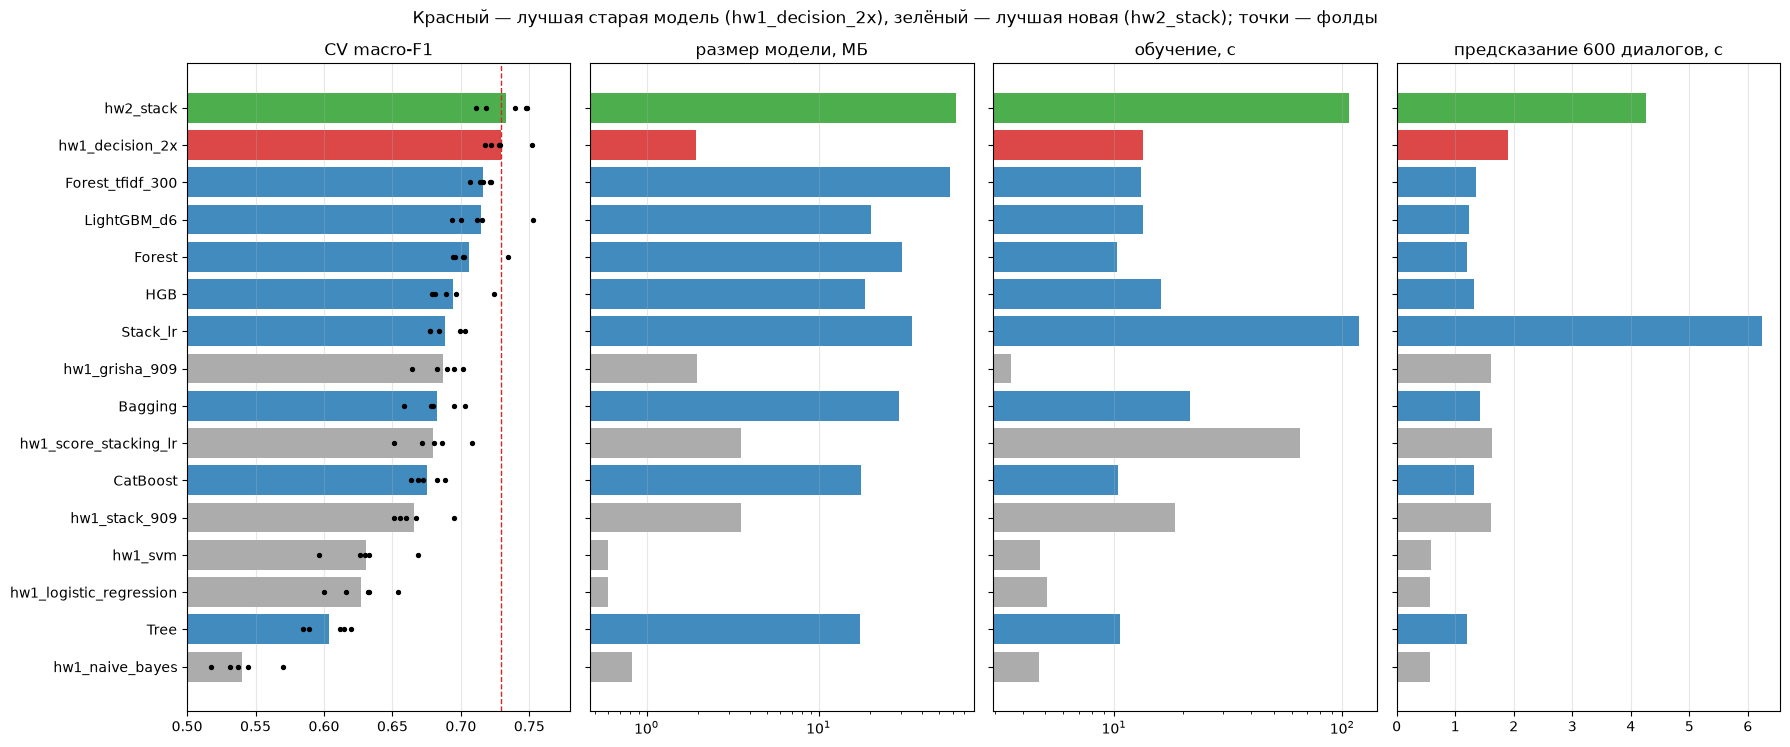

In [11]:
CHART = [*om.OLD_MODELS, "Tree", "Bagging", "Forest", "Forest_tfidf_300", "HGB", "LightGBM_d6", "CatBoost",
         "Stack_lr", "hw2_stack"]
FACTORY = {**om.OLD_MODELS, **E.ALL}
cost_path = Path("artifacts/fold0_cost.json")
cost = json.loads(cost_path.read_text()) if cost_path.exists() else {}
for name in CHART:
    if name not in cost:
        T._cache.clear()
        start = time.perf_counter(); model = FACTORY[name]().fit(fit0); fit_s = time.perf_counter() - start
        start = time.perf_counter(); model.predict(val0); pred_s = time.perf_counter() - start
        cost[name] = dict(fit_seconds=fit_s, predict_seconds=pred_s, size_mb=len(pickle.dumps(model)) / 2**20)
        cost_path.write_text(json.dumps(cost, indent=1))
chart = table.loc[CHART, ["family", "cv_macro_f1", "std", "cv_macro_f1_equal"]].join(pd.DataFrame(cost).T)
display(chart.sort_values("cv_macro_f1", ascending=False))
compare_plot(chart, {n: f1(n) for n in CHART}, "hw1_decision_2x", "hw2_stack", FIG / "comparison.png")

## 8. Ошибки

Матрицы ошибок по OOF-предсказаниям всех 3000 диалогов (строки — истина).

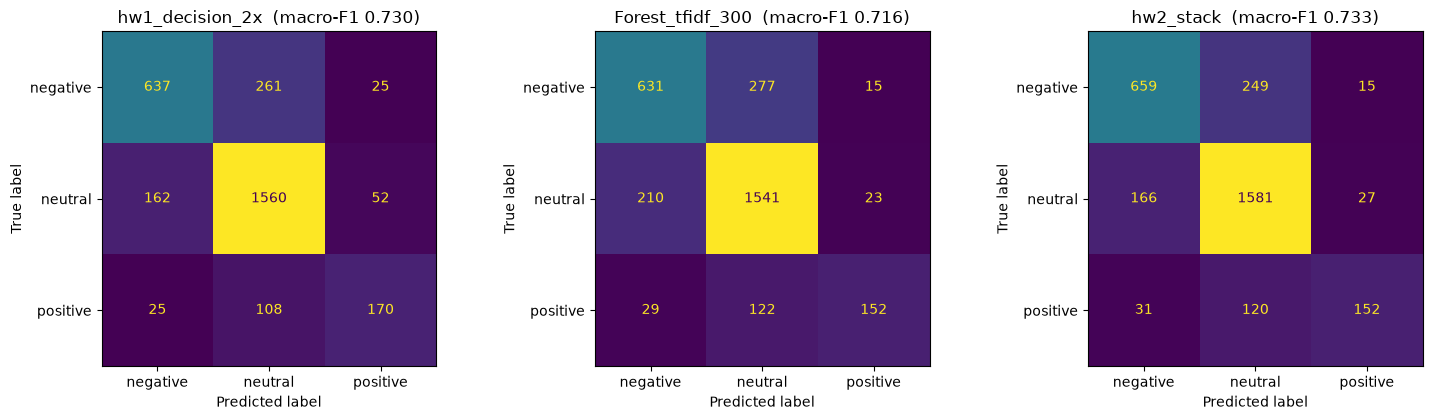

,missed,false_alarm,polarity,total
hw1_decision_2x,369,214,50,633
Forest_tfidf_300,399,233,44,676
LightGBM_d6,319,303,56,678
hw2_stack,369,193,46,608


Decision_2x и Forest_tfidf_300 расходятся на 407 диалогах (13.6%): прав Decision_2x — 210, прав Forest — 167
оракул (на каждом диалоге правильная из двух): macro-F1 0.7989


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, name in zip(axes, ["hw1_decision_2x", "Forest_tfidf_300", "hw2_stack"]):
    ConfusionMatrixDisplay.from_predictions(y, res[name]["pred"], labels=REACTIONS, ax=ax, colorbar=False)
    ax.set_title(f"{name}  (macro-F1 {f1(name).mean():.3f})")
fig.tight_layout(); fig.savefig(FIG / "confusion.png", dpi=130); plt.show()

def error_types(p):
    return dict(missed=((y != "neutral") & (p == "neutral")).sum(), false_alarm=((y == "neutral") & (p != "neutral")).sum(),
                polarity=((y != "neutral") & (p != "neutral") & (y != p)).sum(), total=(y != p).sum())
display(pd.DataFrame({n: error_types(res[n]["pred"]) for n in ["hw1_decision_2x", "Forest_tfidf_300", "LightGBM_d6", "hw2_stack"]}).T)

d, t = res["hw1_decision_2x"]["pred"], res["Forest_tfidf_300"]["pred"]
diff = d != t
oracle = np.where(d == y, d, t)
print(f"Decision_2x и Forest_tfidf_300 расходятся на {diff.sum()} диалогах ({diff.mean():.1%}): "
      f"прав Decision_2x — {((d == y) & diff).sum()}, прав Forest — {((t == y) & diff).sum()}")
print(f"оракул (на каждом диалоге правильная из двух): macro-F1 {np.mean([macro_f1(y[v], oracle[v]) for _, _, v in iter_folds(df)]):.4f}")

## 9. Важность признаков

На фолде 0: модели обучены на 2400 диалогах, перестановочная важность — на репликах
валидации (600 диалогов), метрика macro-F1 по репликам, 5 перестановок.

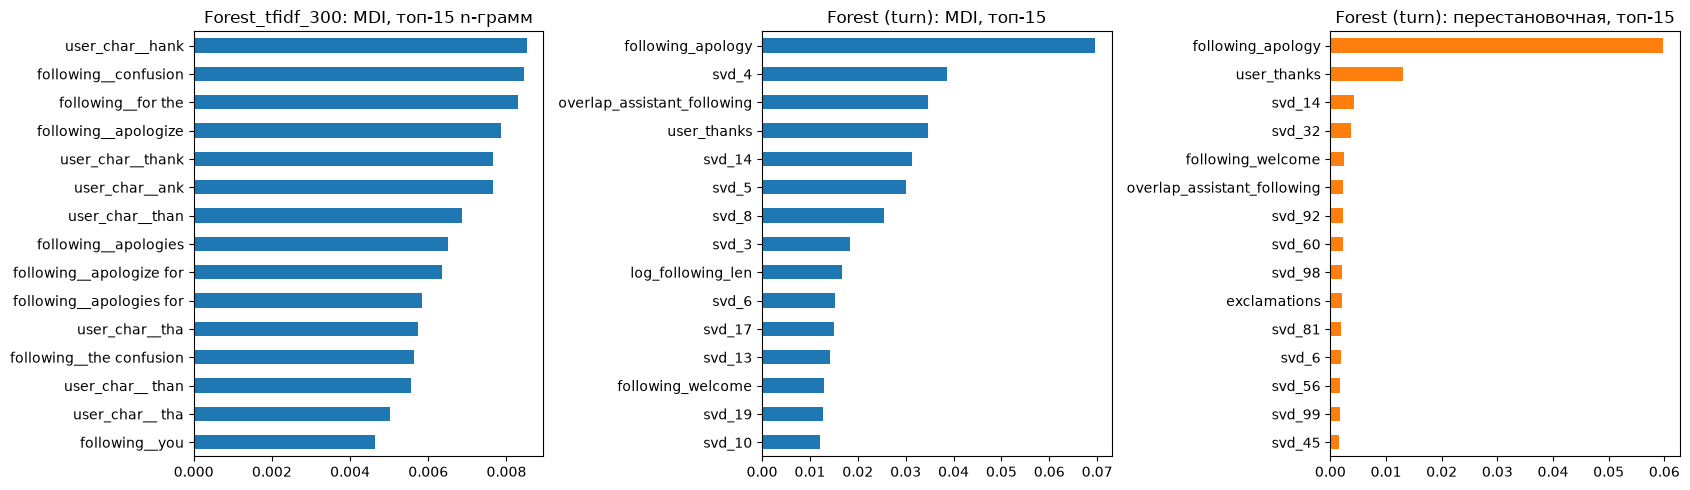

,MDI,permutation,rank_MDI,rank_perm
following_apology,0.0695,0.0598,1,1
user_thanks,0.0347,0.0130,4,2
svd_14,0.0313,0.0042,5,3
svd_32,0.0060,0.0036,46,4
following_welcome,0.0129,0.0025,13,5
overlap_assistant_following,0.0347,0.0023,3,6
svd_92,0.0050,0.0023,92,7
svd_60,0.0045,0.0022,108,8
svd_98,0.0051,0.0021,85,9
exclamations,0.0024,0.0021,117,10


SVD-компонент среди топ-15 MDI: 10 | среди топ-15 перестановочной: 10


In [13]:
forest_tfidf = E.TUNING["Forest_tfidf_300"]().fit(fit0)
mdi_words = pd.Series(forest_tfidf.model.feature_importances_, forest_tfidf.rep.names("raw")).nlargest(15)

forest = E.TREES["Forest"]().fit(fit0)
val_pairs = T.turn_pairs(val0, training=True)
x_val = forest.rep.transform(val0)["turn"]
perm = permutation_importance(forest.model, x_val, val_pairs["reaction"], scoring="f1_macro",
                              n_repeats=5, random_state=42, n_jobs=-1)
imp = pd.DataFrame({"MDI": forest.model.feature_importances_, "permutation": perm.importances_mean},
                   index=forest.rep.names("turn"))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
mdi_words[::-1].plot.barh(ax=axes[0], color="#1f77b4", title="Forest_tfidf_300: MDI, топ-15 n-грамм")
imp["MDI"].nlargest(15)[::-1].plot.barh(ax=axes[1], color="#1f77b4", title="Forest (turn): MDI, топ-15")
imp["permutation"].nlargest(15)[::-1].plot.barh(ax=axes[2], color="#ff7f0e", title="Forest (turn): перестановочная, топ-15")
fig.tight_layout(); fig.savefig(FIG / "importance.png", dpi=130); plt.show()

imp["rank_MDI"] = imp["MDI"].rank(ascending=False).astype(int)
imp["rank_perm"] = imp["permutation"].rank(ascending=False).astype(int)
display(imp.sort_values("permutation", ascending=False).head(15))
print("SVD-компонент среди топ-15 MDI:", imp["MDI"].nlargest(15).index.str.startswith("svd").sum(),
      "| среди топ-15 перестановочной:", imp["permutation"].nlargest(15).index.str.startswith("svd").sum())

## 10. Гипотеза: доли классов на скрытом тесте

В обучении классы 59/31/10% (neutral/negative/positive), на скрытом тесте по README HW1 —
1:1:1. При сдвиге долей macro-F1 моделей, которые «экономят» на редком positive, падает.
Гипотеза: (1) по macro-F1 при равных долях модели с балансировкой выигрывают у лучших по
обычному macro-F1; (2) поправка вероятностей реплик на доли классов
p'(c) ∝ p(c) · (1/3) / π(c) поднимает macro-F1 при равных долях ценой обычного.
Проверяется только на CV, скрытый тест для этого не используется.

доли классов: {'negative': 0.308, 'neutral': 0.591, 'positive': 0.101}  множители: [1.08 0.56 3.3 ]


совпадение с CV hw2_stack: 1.0


,macro-F1,macro-F1 при равных долях
hw1_decision_2x,0.7295,0.7103
hw1_score_stacking_lr,0.6794,0.7318
hw1_grisha_909,0.6867,0.7054
Stack_lr,0.6882,0.7321
Forest_tfidf_300,0.7160,0.6831
hw2_stack,0.7330,0.6987
hw2_stack + поправка на доли,0.7311,0.7335


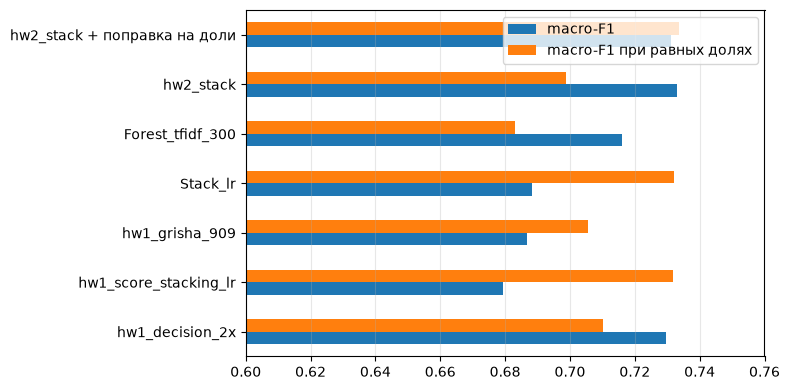

,macro-F1: hw2_stack_prior,macro-F1: hw1_decision_2x,равные доли: hw2_stack_prior,равные доли: hw1_decision_2x
0,0.7212,0.7179,0.7381,0.7058
1,0.7209,0.7220,0.7348,0.6997
2,0.7406,0.7275,0.7386,0.7091
3,0.7338,0.7285,0.7065,0.6941
4,0.7389,0.7517,0.7495,0.7430
mean,0.7311,0.7295,0.7335,0.7103


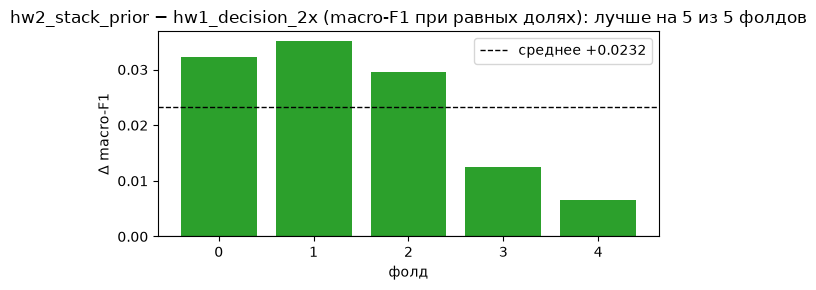

In [14]:
prior = pd.Series(y).value_counts(normalize=True)[REACTIONS]
weights = (1 / 3) / prior.to_numpy()
print("доли классов:", prior.round(3).to_dict(), " множители:", np.round(weights, 2))

def both(pred):
    return (np.mean([macro_f1(y[v], pred[v]) for _, _, v in iter_folds(df)]),
            np.mean([macro_f1(y[v], pred[v], w_eq[v]) for _, _, v in iter_folds(df)]))

stack_meta = variants["LR: SVM + Forest + LightGBM (hw2_stack)"]
plain, _ = S.oof_predict(df, L1T, *stack_meta)
corrected, _ = S.oof_predict(df, L1T, *stack_meta, weights=weights)
print("совпадение с CV hw2_stack:", (plain == res["hw2_stack"]["pred"]).mean())
rows = {n: both(res[n]["pred"]) for n in ["hw1_decision_2x", "hw1_score_stacking_lr", "hw1_grisha_909", "Stack_lr",
                                           "Forest_tfidf_300", "hw2_stack"]}
rows["hw2_stack + поправка на доли"] = both(corrected)
hyp = pd.DataFrame(rows, index=["macro-F1", "macro-F1 при равных долях"]).T
display(hyp)
ax = hyp.plot.barh(figsize=(8, 4), xlim=(0.6, 0.76)); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.savefig(FIG / "hypothesis.png", dpi=130); plt.show()

d2x = res["hw1_decision_2x"]["pred"]
by_fold = pd.DataFrame({
    "macro-F1: hw2_stack_prior": [macro_f1(y[v], corrected[v]) for _, _, v in iter_folds(df)],
    "macro-F1: hw1_decision_2x": [macro_f1(y[v], d2x[v]) for _, _, v in iter_folds(df)],
    "равные доли: hw2_stack_prior": [macro_f1(y[v], corrected[v], w_eq[v]) for _, _, v in iter_folds(df)],
    "равные доли: hw1_decision_2x": [macro_f1(y[v], d2x[v], w_eq[v]) for _, _, v in iter_folds(df)],
})
by_fold.loc["mean"] = by_fold.mean()
display(by_fold)
eq = pd.DataFrame({"delta": by_fold.iloc[:, 2] - by_fold.iloc[:, 3]})
paired_plot(eq, "hw2_stack_prior", "hw1_decision_2x (macro-F1 при равных долях)", FIG / "paired_delta_equal.png")

## 11. Финальные модели

`python train_final.py` обучает `hw2_*` на всех 3000 диалогах и сохраняет в `artifacts/`;
`solution.ipynb` грузит их вместе с `hw1_*`.

In [15]:
final = pd.DataFrame({"fit_seconds": json.loads(Path("artifacts/hw2_fit_seconds.json").read_text())})
final["file_mb"] = [Path(f"artifacts/{n}.joblib").stat().st_size / 2**20 for n in final.index]
final["cv_macro_f1"] = [f1({"hw2_random_forest": "Forest_tfidf_300", "hw2_hgb": "HGB", "hw2_lightgbm": "LightGBM_d6",
                            "hw2_stack": "hw2_stack"}[n]).mean() if n != "hw2_stack_prior" else hyp.loc["hw2_stack + поправка на доли", "macro-F1"]
                     for n in final.index]
final["cv_macro_f1_equal"] = [table.loc[{"hw2_random_forest": "Forest_tfidf_300", "hw2_hgb": "HGB", "hw2_lightgbm": "LightGBM_d6",
                                         "hw2_stack": "hw2_stack"}[n], "cv_macro_f1_equal"] if n != "hw2_stack_prior"
                              else hyp.loc["hw2_stack + поправка на доли", "macro-F1 при равных долях"] for n in final.index]
display(final)

import joblib
stack = joblib.load("artifacts/hw2_stack.joblib")
coef = pd.DataFrame(stack.meta_[-1].coef_, index=stack.meta_[-1].classes_,
                    columns=["svm_pos", "svm_neg", "forest_neg", "forest_neu", "forest_pos", "lgbm_neg", "lgbm_neu", "lgbm_pos"])
print("порог hw2_stack:", stack.threshold)
display(coef.round(2))

,fit_seconds,file_mb,cv_macro_f1,cv_macro_f1_equal
hw2_random_forest,16.8,29.7181,0.7160,0.6831
hw2_hgb,7.2,15.6343,0.6940,0.6902
hw2_lightgbm,3.9,16.4669,0.7147,0.6905
hw2_stack,122.3,32.0410,0.7330,0.6987
hw2_stack_prior,100.0,32.0411,0.7311,0.7335


порог hw2_stack: 0.47500000000000014


,svm_pos,svm_neg,forest_neg,forest_neu,forest_pos,lgbm_neg,lgbm_neu,lgbm_pos
negative,-0.18,0.61,0.15,-0.04,-0.17,0.13,-0.13,0.04
neutral,-0.32,-0.39,-0.05,0.12,-0.12,-0.11,0.13,-0.07
positive,0.50,-0.21,-0.10,-0.08,0.30,-0.02,0.00,0.03


## Итог

| | CV macro-F1 | при равных долях | лучше Decision_2x по фолдам |
|:--|--:|--:|:--|
| hw1_decision_2x (лучшая старая) | 0.7295 | 0.7103 | — |
| **hw2_stack** (лучшая новая) | **0.7330** | 0.6987 | 2 из 5 |
| **hw2_stack_prior** (то же + поправка на доли) | 0.7311 | **0.7335** | 3 из 5 / **5 из 5** |
| Forest_tfidf_300 (лучшее отдельное дерево) | 0.7160 | 0.6831 | 0 из 5 |
| LightGBM_d6 (лучший бустинг) | 0.7147 | 0.6905 | — |

1. Отдельные деревья и бустинг на репликах упираются в ~0.715: линейный SVM на 42k
   TF-IDF-признаках (Decision_2x) сильнее любого одиночного дерева.
2. Лучшая новая модель — стекинг на OOF по репликам из старой модели (SVM Decision_2x)
   и двух ансамблей. Она обходит лучшую старую по среднему CV macro-F1 (+0.0035), но
   прирост меньше разброса фолдов (±0.015): по сути это паритет. Вариант выбран из
   нескольких по внешней CV, оценка слегка оптимистична.
3. Стек по сводкам диалога (как у коллег) хуже стека по репликам: Decision_2x и деревья
   расходятся в выборе решающей реплики, а сводка диалога это теряет.
4. Веса классов в мета-модели (`balanced`) снижают macro-F1 на ~0.02–0.04, зато
   поднимают macro-F1 при равных долях — та же картина у стеков HW1.
5. Гипотеза подтверждена на CV: поправка вероятностей реплик на доли классов (без
   подбора) даёт `hw2_stack_prior`, который при равных долях лучше Decision_2x на всех
   5 фолдах (+0.023), сохраняя обычный macro-F1. Для скрытого теста с балансом 1:1:1
   это основной кандидат.
6. Главная ошибка всех моделей — пропущенная реакция (≈370 из ≈620 ошибок); около 400
   диалогов не распознаёт ни одна модель.